In [2]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import itertools
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_ind_from_stats
from matplotlib.colors import to_rgba

In [3]:
# load dfs

# OG 7
act_OG7_sf = pd.read_parquet('shakeflasks runs/act_OG_7_summary.parquet')
OD_OG7_sf = pd.read_parquet('shakeflasks runs/OD_OG_7_summary.parquet')
act_OG7_batch = pd.read_parquet('batch runs 700 mL/act_OG7_summary.parquet')
OD_OG7_batch = pd.read_parquet('batch runs 700 mL/OD_OG7_summary.parquet')

# OG 8
act_OG8_sf = pd.read_parquet('shakeflasks runs/act_OG_8_summary.parquet')
OD_OG8_sf = pd.read_parquet('shakeflasks runs/OD_OG_8_summary.parquet')
act_OG8_batch = pd.read_parquet('batch runs 700 mL/act_OG8_summary.parquet')
OD_OG8_batch = pd.read_parquet('batch runs 700 mL/OD_OG8_summary.parquet')

# ALE 7
act_ALE7_sf = pd.read_parquet('shakeflasks runs/act_ALE_7_summary.parquet')
OD_ALE7_sf = pd.read_parquet('shakeflasks runs/OD_ALE_7_summary.parquet')
act_ALE7_batch = pd.read_parquet('batch runs 700 mL/act_ALE7_summary.parquet')
OD_ALE7_batch = pd.read_parquet('batch runs 700 mL/OD_ALE7_summary.parquet')

# ALE 8
act_ALE8_sf = pd.read_parquet('shakeflasks runs/act_ALE_8_summary.parquet')
OD_ALE8_sf = pd.read_parquet('shakeflasks runs/OD_ALE_8_summary.parquet')
act_ALE8_batch = pd.read_parquet('batch runs 700 mL/act_ALE8_summary.parquet')
OD_ALE8_batch = pd.read_parquet('batch runs 700 mL/OD_ALE8_summary.parquet')

# ALE 9
act_ALE9_sf = pd.read_parquet('shakeflasks runs/act_ALE_9_summary.parquet')
OD_ALE9_sf = pd.read_parquet('shakeflasks runs/OD_ALE_9_summary.parquet')
act_ALE9_batch = pd.read_parquet('batch runs 700 mL/act_ALE9_summary.parquet')
OD_ALE9_batch = pd.read_parquet('batch runs 700 mL/OD_ALE9_summary.parquet')

In [5]:
# ---------- significance functions ----------

def extract_pool5(dfs, prefix):
    data = {}
    for name, df in dfs.items():
        row = df[df[f"{prefix}_pool"] == 5].iloc[0]
        data[name] = {
            "mean": row[f"{prefix}_mean"],
            "std": row[f"{prefix}_std"],
            "n": row[f"{prefix}_n"],
        }
    return data

# pairwise comparisons
def planned_pairwise_tests(data, pairs, adjust_method="holm"):
    results = []

    for g1, g2 in pairs:
        d1 = data[g1]
        d2 = data[g2]

        t, p = ttest_ind_from_stats(
            mean1=d1["mean"], std1=d1["std"], nobs1=d1["n"],
            mean2=d2["mean"], std2=d2["std"], nobs2=d2["n"],
            equal_var=False
        )

        results.append({
            "group1": g1,
            "group2": g2,
            "p_value": p
        })

    results = pd.DataFrame(results)

    if len(results) > 0:
        _, p_adj, _, _ = multipletests(results["p_value"], method=adjust_method)
        results["p_adj"] = p_adj
        results["stars"] = results["p_adj"].apply(p_to_stars)

    return results

# correct for mutiple testing
def adjust_pvalues(df):
    _, p_adj, _, _ = multipletests(df["p_value"], method="holm")
    df["p_adj"] = p_adj
    return df

# ---------- plotting helpers ----------
def p_to_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""


def df_to_bracket_pairs(df, xmap, p_col="p_adj"):
    pairs = []

    for _, row in df.iterrows():
        label = row["stars"] if "stars" in df.columns else p_to_stars(row[p_col])
        if label == "":
            continue

        pairs.append({
            "x1": xmap[row["group1"]],
            "x2": xmap[row["group2"]],
            "label": label,
            "group1": row["group1"],
            "group2": row["group2"],
        })

    return pairs


def add_sig_bracket(ax, x1, x2, y, h, text):
    ax.plot([x1, x1, x2, x2], [y, y+h, y+h, y],
            linewidth=1, color="black")
    ax.text((x1 + x2) / 2, y + h, text,
            ha="center", va="bottom", fontsize=10)

def add_sig_brackets_grouped(ax, bracket_pairs, height_lookup, h=None, gap=None, text_offset=None):
    """
    bracket_pairs: list of dicts with keys x1, x2, label, group1, group2
    height_lookup: dict mapping each bar key to top y-value (mean + std)
    """
    if not bracket_pairs:
        return

    all_tops = [v for v in height_lookup.values() if not np.isnan(v)]
    ymax = max(all_tops)

    if h is None:
        h = 0.03 * ymax if ymax > 0 else 0.05
    if gap is None:
        gap = 0.05 * ymax if ymax > 0 else 0.08
    if text_offset is None:
        text_offset = 0.01 * ymax if ymax > 0 else 0.02

    current_top = ymax

    for pair in bracket_pairs:
        local_top = max(height_lookup[pair["group1"]], height_lookup[pair["group2"]])
        y = local_top + gap
        add_sig_bracket(ax, pair["x1"], pair["x2"], y, h, pair["label"])
        current_top = max(current_top, y + h + text_offset)

    ax.set_ylim(top=current_top + gap)

In [ ]:
# calculate significance
# define comparisons
pairs = [
    ("OG7_sf", "OG7_batch"),
    ("OG8_sf", "OG8_batch"),
    ("ALE7_sf", "ALE7_batch"),
    ("ALE8_sf", "ALE8_batch"),
    ("ALE9_sf", "ALE9_batch"),
]


# volumetric activity
# stats dictionary
vol_stats = {
    "OG7_sf":    {"mean": act_OG7_sf['vol_mean'].iloc[-1],    "std": act_OG7_sf['vol_std'].iloc[-1],    "n": act_OG7_sf['vol_n'].iloc[-1]},
    "OG7_batch": {"mean": act_OG7_batch['vol_mean'].iloc[-1],  "std": act_OG7_batch['vol_std'].iloc[-1],  "n": act_OG7_batch['vol_n'].iloc[-1]},
    "OG8_sf":    {"mean": act_OG8_sf['vol_mean'].iloc[-1],    "std": act_OG8_sf['vol_std'].iloc[-1],    "n": act_OG8_sf['vol_n'].iloc[-1]},
    "OG8_batch": {"mean": act_OG8_batch['vol_mean'].iloc[-1],  "std": act_OG8_batch['vol_std'].iloc[-1],  "n": act_OG8_batch['vol_n'].iloc[-1]},
    "ALE7_sf":   {"mean": act_ALE7_sf['vol_mean'].iloc[-1],   "std": act_ALE7_sf['vol_std'].iloc[-1],   "n": act_ALE7_sf['vol_n'].iloc[-1]},
    "ALE7_batch":{"mean": act_ALE7_batch['vol_mean'].iloc[-1], "std": act_ALE7_batch['vol_std'].iloc[-1], "n": act_ALE7_batch['vol_n'].iloc[-1]},
    "ALE8_sf":   {"mean": act_ALE8_sf['vol_mean'].iloc[-1],   "std": act_ALE8_sf['vol_std'].iloc[-1],   "n": act_ALE8_sf['vol_n'].iloc[-1]},
    "ALE8_batch":{"mean": act_ALE8_batch['vol_mean'].iloc[-1], "std": act_ALE8_batch['vol_std'].iloc[-1], "n": act_ALE8_batch['vol_n'].iloc[-1]},
    "ALE9_sf":   {"mean": act_ALE9_sf['vol_mean'].iloc[-1],   "std": act_ALE9_sf['vol_std'].iloc[-1],   "n": act_ALE9_sf['vol_n'].iloc[-1]},
    "ALE9_batch":{"mean": act_ALE9_batch['vol_mean'].iloc[-1], "std": act_ALE9_batch['vol_std'].iloc[-1], "n": act_ALE9_batch['vol_n'].iloc[-1]},
}

# normalized activity
# stats dictionary
norm_stats = {
    "OG7_sf":    {"mean": act_OG7_sf['norm_mean'].iloc[-1],    "std": act_OG7_sf['norm_std'].iloc[-1],    "n": act_OG7_sf['norm_n'].iloc[-1]},
    "OG7_batch": {"mean": act_OG7_batch['norm_mean'].iloc[-1],  "std": act_OG7_batch['norm_std'].iloc[-1],  "n": act_OG7_batch['norm_n'].iloc[-1]},
    "OG8_sf":    {"mean": act_OG8_sf['norm_mean'].iloc[-1],    "std": act_OG8_sf['norm_std'].iloc[-1],    "n": act_OG8_sf['norm_n'].iloc[-1]},
    "OG8_batch": {"mean": act_OG8_batch['norm_mean'].iloc[-1],  "std": act_OG8_batch['norm_std'].iloc[-1],  "n": act_OG8_batch['norm_n'].iloc[-1]},
    "ALE7_sf":   {"mean": act_ALE7_sf['norm_mean'].iloc[-1],   "std": act_ALE7_sf['norm_std'].iloc[-1],   "n": act_ALE7_sf['norm_n'].iloc[-1]},
    "ALE7_batch":{"mean": act_ALE7_batch['norm_mean'].iloc[-1], "std": act_ALE7_batch['norm_std'].iloc[-1], "n": act_ALE7_batch['norm_n'].iloc[-1]},
    "ALE8_sf":   {"mean": act_ALE8_sf['norm_mean'].iloc[-1],   "std": act_ALE8_sf['norm_std'].iloc[-1],   "n": act_ALE8_sf['norm_n'].iloc[-1]},
    "ALE8_batch":{"mean": act_ALE8_batch['norm_mean'].iloc[-1], "std": act_ALE8_batch['norm_std'].iloc[-1], "n": act_ALE8_batch['norm_n'].iloc[-1]},
    "ALE9_sf":   {"mean": act_ALE9_sf['norm_mean'].iloc[-1],   "std": act_ALE9_sf['norm_std'].iloc[-1],   "n": act_ALE9_sf['norm_n'].iloc[-1]},
    "ALE9_batch":{"mean": act_ALE9_batch['norm_mean'].iloc[-1], "std": act_ALE9_batch['norm_std'].iloc[-1], "n": act_ALE9_batch['norm_n'].iloc[-1]},
}

# OD
# stats dictionary
od_stats = {
    "OG7_sf":    {"mean": OD_OG7_sf['mean_1_3'].iloc[-1],    "std": OD_OG7_sf['std_1_3'].iloc[-1],    "n": 3},
    "OG7_batch": {"mean": OD_OG7_batch['mean_OD'].iloc[-1],  "std": OD_OG7_batch['std_OD'].iloc[-1],  "n": 3},
    "OG8_sf":    {"mean": OD_OG8_sf['mean_1_3'].iloc[-1],    "std": OD_OG8_sf['std_1_3'].iloc[-1],    "n": 3},
    "OG8_batch": {"mean": OD_OG8_batch['mean_OD'].iloc[-1],  "std": OD_OG8_batch['std_OD'].iloc[-1],  "n": 3},
    "ALE7_sf":   {"mean": OD_ALE7_sf['mean_1_3'].iloc[-1],   "std": OD_ALE7_sf['std_1_3'].iloc[-1],   "n": 3},
    "ALE7_batch":{"mean": OD_ALE7_batch['mean_OD'].iloc[-1], "std": OD_ALE7_batch['std_OD'].iloc[-1], "n": 3},
    "ALE8_sf":   {"mean": OD_ALE8_sf['mean_1_3'].iloc[-1],   "std": OD_ALE8_sf['std_1_3'].iloc[-1],   "n": 3},
    "ALE8_batch":{"mean": OD_ALE8_batch['mean_OD'].iloc[-1], "std": OD_ALE8_batch['std_OD'].iloc[-1], "n": 3},
    "ALE9_sf":   {"mean": OD_ALE9_sf['mean_1_3'].iloc[-1],   "std": OD_ALE9_sf['std_1_3'].iloc[-1],   "n": 3},
    "ALE9_batch":{"mean": OD_ALE9_batch['mean_OD'].iloc[-1], "std": OD_ALE9_batch['std_OD'].iloc[-1], "n": 3},
}

# run test
vol_results = planned_pairwise_tests(vol_stats, pairs, adjust_method="holm")
norm_results = planned_pairwise_tests(norm_stats, pairs, adjust_method="holm")
od_results = planned_pairwise_tests(od_stats, pairs, adjust_method="holm")

# print results
print(vol_results)
print(norm_results)
print(od_results)

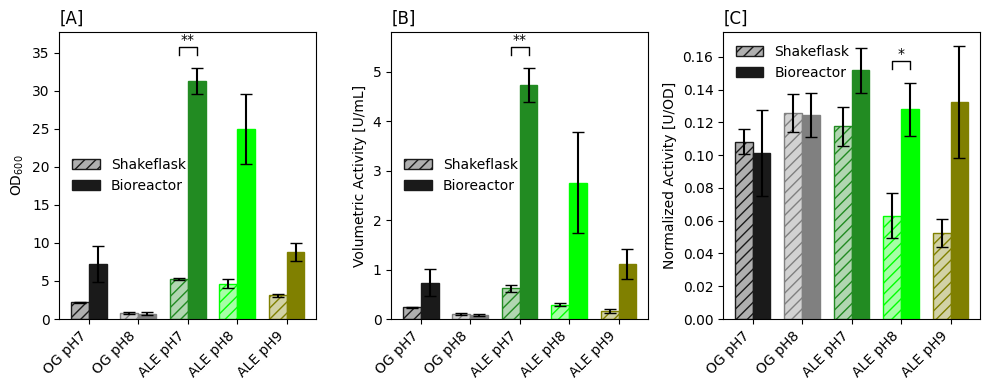

In [ ]:
# PLOTS
x = [2, 4, 6, 8, 24]

# ---------------- Figure layout ----------------
fig, axs = plt.subplots(1, 3, figsize=(10, 4))

ax_A = axs[0]   # OD endpoint
ax_B = axs[1]   # volumetric endpoint
ax_C = axs[2]   # normalized endpoint

width = 0.36 # for columns

# ---------------- Common styling ----------------
groups = ['OG pH7', 'OG pH8', 'ALE pH7', 'ALE pH8', 'ALE pH9']
colors = ['0.1', '0.5', 'forestgreen', 'lime', 'olive']
xpos = np.arange(len(groups))

# ---------------- A: OD endpoint ----------------
# mean
OD_sf_mean = [
    OD_OG7_sf['mean_1_3'].iloc[-1],
    OD_OG8_sf['mean_1_3'].iloc[-1],
    OD_ALE7_sf['mean_1_3'].iloc[-1],
    OD_ALE8_sf['mean_1_3'].iloc[-1],
    OD_ALE9_sf['mean_1_3'].iloc[-1],
]

OD_batch_mean = [
    OD_OG7_batch['mean_OD'].iloc[-1],
    OD_OG8_batch['mean_OD'].iloc[-1],
    OD_ALE7_batch['mean_OD'].iloc[-1],
    OD_ALE8_batch['mean_OD'].iloc[-1],
    OD_ALE9_batch['mean_OD'].iloc[-1],
]

# std
OD_sf_std = [
    OD_OG7_sf['std_1_3'].iloc[-1],
    OD_OG8_sf['std_1_3'].iloc[-1],
    OD_ALE7_sf['std_1_3'].iloc[-1],
    OD_ALE8_sf['std_1_3'].iloc[-1],
    OD_ALE9_sf['std_1_3'].iloc[-1],
]

OD_batch_std = [
    OD_OG7_batch['std_OD'].iloc[-1],
    OD_OG8_batch['std_OD'].iloc[-1],
    OD_ALE7_batch['std_OD'].iloc[-1],
    OD_ALE8_batch['std_OD'].iloc[-1],
    OD_ALE9_batch['std_OD'].iloc[-1],
]

# SF bars
for i, (mean, std, c) in enumerate(zip(OD_sf_mean, OD_sf_std, colors)):
    if not np.isnan(mean):
        ax_A.bar(
            xpos[i] - width/2,
            mean,
            width=width,
            yerr=std,
            capsize=4,
            facecolor=to_rgba(c, 0.35),   # lighter fill
            edgecolor=c,                  # hatch + border in same full color
            hatch='///',
            linewidth=1.0,
            label='Shakeflask' if i == 0 else ""
        )

# Batch bars
for i, (mean, std, c) in enumerate(zip(OD_batch_mean, OD_batch_std, colors)):
    ax_A.bar(
        xpos[i] + width/2,
        mean,
        width=width,
        yerr=std,
        capsize=4,
        color=c,
        edgecolor=c,
        linewidth=1.0,
        label='Bioreactor' if i == 0 else ""
    )

ax_A.set_xticks(xpos)
ax_A.set_xticklabels(groups, rotation=45, ha='right')
ax_A.set_ylabel("OD$_{600}$")
ax_A.set_title('[A]', loc='left')
ax_A.set_ylim(bottom=0)
ax_A.legend(frameon=False)

# ---------------- B: volumetric endpoint ----------------
# mean
vol_sf_mean = [
    act_OG7_sf['vol_mean'].iloc[-1],
    act_OG8_sf['vol_mean'].iloc[-1],
    act_ALE7_sf['vol_mean'].iloc[-1],
    act_ALE8_sf['vol_mean'].iloc[-1],
    act_ALE9_sf['vol_mean'].iloc[-1],
]

vol_batch_mean = [
    act_OG7_batch['vol_mean'].iloc[-1],
    act_OG8_batch['vol_mean'].iloc[-1],
    act_ALE7_batch['vol_mean'].iloc[-1],
    act_ALE8_batch['vol_mean'].iloc[-1],
    act_ALE9_batch['vol_mean'].iloc[-1],
]

# std
vol_sf_std = [
    act_OG7_sf['vol_std'].iloc[-1],
    act_OG8_sf['vol_std'].iloc[-1],
    act_ALE7_sf['vol_std'].iloc[-1],
    act_ALE8_sf['vol_std'].iloc[-1],
    act_ALE9_sf['vol_std'].iloc[-1],
]

vol_batch_std = [
    act_OG7_batch['vol_std'].iloc[-1],
    act_OG8_batch['vol_std'].iloc[-1],
    act_ALE7_batch['vol_std'].iloc[-1],
    act_ALE8_batch['vol_std'].iloc[-1],
    act_ALE9_batch['vol_std'].iloc[-1],
]
# SF bars
for i, (mean, std, c) in enumerate(zip(vol_sf_mean, vol_sf_std, colors)):
    if not np.isnan(mean):
        ax_B.bar(
            xpos[i] - width/2,
            mean,
            width=width,
            yerr=std,
            capsize=4,
            facecolor=to_rgba(c, 0.35),   # lighter fill
            edgecolor=c,                  # hatch + border in same full color
            hatch='///',
            linewidth=1.0,
            label='Shakeflask' if i == 0 else ""
        )

# Batch bars
for i, (mean, std, c) in enumerate(zip(vol_batch_mean, vol_batch_std, colors)):
    ax_B.bar(
        xpos[i] + width/2,
        mean,
        width=width,
        yerr=std,
        capsize=4,
        color=c,
        edgecolor=c,
        linewidth=1.0,
        label='Bioreactor' if i == 0 else ""
    )

ax_B.set_xticks(xpos)
ax_B.set_xticklabels(groups, rotation=45, ha='right')
ax_B.set_ylabel("Volumetric Activity [U/mL]")
ax_B.set_title('[B]', loc='left')
ax_B.set_ylim(bottom=0)
ax_B.legend(frameon=False)

# ---------------- C: normalized endpoint ----------------
# mean
norm_sf_mean = [
    act_OG7_sf['norm_mean'].iloc[-1],
    act_OG8_sf['norm_mean'].iloc[-1],
    act_ALE7_sf['norm_mean'].iloc[-1],
    act_ALE8_sf['norm_mean'].iloc[-1],
    act_ALE9_sf['norm_mean'].iloc[-1],
]

norm_batch_mean = [
    act_OG7_batch['norm_mean'].iloc[-1],
    act_OG8_batch['norm_mean'].iloc[-1],
    act_ALE7_batch['norm_mean'].iloc[-1],
    act_ALE8_batch['norm_mean'].iloc[-1],
    act_ALE9_batch['norm_mean'].iloc[-1],
]

# std
norm_sf_std = [
    act_OG7_sf['norm_std'].iloc[-1],
    act_OG8_sf['norm_std'].iloc[-1],
    act_ALE7_sf['norm_std'].iloc[-1],
    act_ALE8_sf['norm_std'].iloc[-1],
    act_ALE9_sf['norm_std'].iloc[-1],
]

norm_batch_std = [
    act_OG7_batch['norm_std'].iloc[-1],
    act_OG8_batch['norm_std'].iloc[-1],
    act_ALE7_batch['norm_std'].iloc[-1],
    act_ALE8_batch['norm_std'].iloc[-1],
    act_ALE9_batch['norm_std'].iloc[-1],
]
# SF bars
for i, (mean, std, c) in enumerate(zip(norm_sf_mean, norm_sf_std, colors)):
    if not np.isnan(mean):
        ax_C.bar(
            xpos[i] - width/2,
            mean,
            width=width,
            yerr=std,
            capsize=4,
            facecolor=to_rgba(c, 0.35),   # lighter fill
            edgecolor=c,                  # hatch + border in same full color
            hatch='///',
            linewidth=1.0,
            label='Shakeflask' if i == 0 else ""
        )

# Batch bars
for i, (mean, std, c) in enumerate(zip(norm_batch_mean, norm_batch_std, colors)):
    ax_C.bar(
        xpos[i] + width/2,
        mean,
        width=width,
        yerr=std,
        capsize=4,
        color=c,
        edgecolor=c,
        linewidth=1.0,
        label='Bioreactor' if i == 0 else ""
    )
    
ax_C.set_xticks(xpos)
ax_C.set_xticklabels(groups, rotation=45, ha='right')
ax_C.set_ylabel("Normalized Activity [U/OD]")
ax_C.set_title('[C]', loc='left')
ax_C.set_ylim(bottom=0)
ax_C.legend(frameon=False)


# ---------------- significance brackets ----------------
# x positions
xmap = {
    "OG7_sf": xpos[0] - width/2,
    "OG7_batch": xpos[0] + width/2,
    "OG8_sf": xpos[1] - width/2,
    "OG8_batch": xpos[1] + width/2,
    "ALE7_sf": xpos[2] - width/2,
    "ALE7_batch": xpos[2] + width/2,
    "ALE8_sf": xpos[3] - width/2,
    "ALE8_batch": xpos[3] + width/2,
    "ALE9_sf": xpos[4] - width/2,
    "ALE9_batch": xpos[4] + width/2,
}

# heights
height_lookup_vol = {k: v["mean"] + v["std"] for k, v in vol_stats.items()}
height_lookup_norm = {k: v["mean"] + v["std"] for k, v in norm_stats.items()}
height_lookup_od = {k: v["mean"] + v["std"] for k, v in od_stats.items()}

# bracket specs
bracket_pairs_A = df_to_bracket_pairs(od_results, xmap)
bracket_pairs_B = df_to_bracket_pairs(vol_results, xmap)
bracket_pairs_C = df_to_bracket_pairs(norm_results, xmap)
bracket_pairs_ = df_to_bracket_pairs(od_results, xmap)

# draw
add_sig_brackets_grouped(ax_A, bracket_pairs_A, height_lookup_od)
add_sig_brackets_grouped(ax_B, bracket_pairs_B, height_lookup_vol)
add_sig_brackets_grouped(ax_C, bracket_pairs_C, height_lookup_norm)


plt.tight_layout()

#plt.savefig("Figure4.tiff", dpi=1000, bbox_inches="tight")
plt.show()